In [82]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,ConfusionMatrixDisplay,confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Dataa

In [83]:
df = pd.read_csv('/content/lung_cancer_examples.csv')
df.head(10)

,Name,Surname,Age,Smokes,AreaQ,Alkhol,Result
0,John,Wick,35,3,5,4,1
1,John,Constantine,27,20,2,5,1
2,Camela,Anderson,30,0,5,2,0
3,Alex,Telles,28,0,8,1,0
4,Diego,Maradona,68,4,5,6,1
5,Cristiano,Ronaldo,34,0,10,0,0
6,Mihail,Tal,58,15,10,0,0
7,Kathy,Bates,22,12,5,2,0
8,Nicole,Kidman,45,2,6,0,0
9,Ray,Milland,52,18,4,5,1


# Data Properties

In [84]:
df.shape

(59, 7)

In [85]:
df.describe()

,Age,Smokes,AreaQ,Alkhol,Result
count,59.000000,59.000000,59.000000,59.000000,59.000000
mean,42.627119,15.067797,5.203390,3.237288,0.474576
std,16.235230,7.984607,2.461984,2.380517,0.503640
min,18.000000,0.000000,1.000000,0.000000,0.000000
25%,29.000000,10.000000,3.000000,1.000000,0.000000
50%,39.000000,15.000000,5.000000,3.000000,0.000000
75%,55.000000,20.000000,7.500000,5.000000,1.000000
max,77.000000,34.000000,10.000000,8.000000,1.000000


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Name     59 non-null     object
 1   Surname  59 non-null     object
 2   Age      59 non-null     int64 
 3   Smokes   59 non-null     int64 
 4   AreaQ    59 non-null     int64 
 5   Alkhol   59 non-null     int64 
 6   Result   59 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 3.4+ KB


In [87]:
df.isna().sum()

,0
Name,0
Surname,0
Age,0
Smokes,0
AreaQ,0
Alkhol,0
Result,0


# Data Exploration

In [88]:
df['Result'].value_counts()

,count
Result,
0,31
1,28


<Axes: xlabel='Result', ylabel='count'>

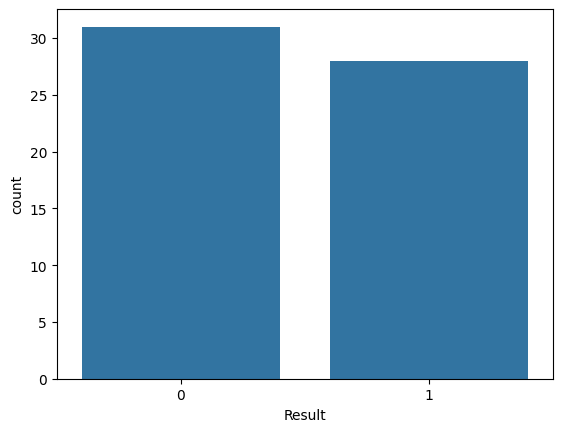

In [89]:
sns.countplot(data=df,x=df['Result'])

# Data Preprocessing

In [90]:
df.head(10)

,Name,Surname,Age,Smokes,AreaQ,Alkhol,Result
0,John,Wick,35,3,5,4,1
1,John,Constantine,27,20,2,5,1
2,Camela,Anderson,30,0,5,2,0
3,Alex,Telles,28,0,8,1,0
4,Diego,Maradona,68,4,5,6,1
5,Cristiano,Ronaldo,34,0,10,0,0
6,Mihail,Tal,58,15,10,0,0
7,Kathy,Bates,22,12,5,2,0
8,Nicole,Kidman,45,2,6,0,0
9,Ray,Milland,52,18,4,5,1


In [91]:
df.drop(['Name','Surname'],axis=1,inplace=True)

In [92]:
df.head(10)

,Age,Smokes,AreaQ,Alkhol,Result
0,35,3,5,4,1
1,27,20,2,5,1
2,30,0,5,2,0
3,28,0,8,1,0
4,68,4,5,6,1
5,34,0,10,0,0
6,58,15,10,0,0
7,22,12,5,2,0
8,45,2,6,0,0
9,52,18,4,5,1


In [93]:
# Features And Labels

In [94]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

# Features Scalling/Normalisatiion

In [95]:
scaler= StandardScaler()
scaler.fit(x)
x = scaler.transform(x)

# Train Split Data

In [96]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.33,random_state=42)

# Build Model

In [97]:
model = KNeighborsClassifier(n_neighbors=13)
model.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=13)

In [98]:
y_pred = model.predict(x_test)

# Confution Metrix

In [99]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[12,  0],
       [ 1,  7]])

# Accuracy Score

In [100]:
score = accuracy_score(y_test,y_pred)
score

0.95

In [101]:
for i in range(5,21):
  model = KNeighborsClassifier(n_neighbors=i)
  model.fit(x_train,y_train)
  y_pred = model.predict(x_test)
  score = accuracy_score(y_pred,y_test)
  print(i,"=",score)

5 = 0.95
6 = 0.95
7 = 0.95
8 = 0.95
9 = 0.95
10 = 0.95
11 = 0.95
12 = 0.95
13 = 0.95
14 = 0.95
15 = 0.95
16 = 0.95
17 = 0.95
18 = 0.95
19 = 0.95
20 = 0.95
